<a href="https://colab.research.google.com/github/subhashraj3031/AlmaBetter_Project/blob/main/DeepFER_Capstone_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DeepFER Facial Expression Recognition
## Capstone project in deep learning for computer vision
**Project type:** Multiclass image classification  
**Contribution:** Individual or team details to be completed by the student  
**Repository:** Add your repository URL if required by your institution.

This notebook implements data auditing, deterministic cleaning, leakage checks, exploratory analysis, CNN and attention experiments, MobileNetV2 transfer learning, held-out evaluation, interpretability and inference. It follows the relevant structure of the supplied ML submission template. Text tokenization and other NLP-only template sections do not apply to face images.

### Start here
1. Select **Runtime → Change runtime type → GPU** if available.
2. Run the notebook from the top. Authorize Google Drive when prompted.
3. The dataset archive is expected at `/content/drive/MyDrive/DeepFER_Images.zip`. Change `DRIVE_ZIP` if you move it. An upload alternative is available in configuration.
4. Results and checkpoints are saved to a dated folder in `MyDrive/DeepFER_Runs`. Training may take several hours depending on the runtime. No payment or additional compute purchase is required by this notebook.

**Execution status:** This notebook is delivered without fabricated outputs. Training and predictive evaluation must run in your Colab runtime. Syntax, cleaning logic and archive integrity were checked locally; TensorFlow training was not available locally.

### Project summary
DeepFER classifies cropped face images into angry, disgust, fear, happy, neutral, sad and surprise. The local audit identified 35,887 canonical JPEG images, all 48 by 48 grayscale pixels. The original folder structure contains 28,821 training and 7,066 validation candidates. A nested folder repeats the entire inventory and must not be loaded as additional data. These figures are prior audit observations; the notebook recomputes its own evidence from the supplied archive.

Data integrity is central to the experiment. The prior audit found 1,853 excess exact-image copies, including repeated content across the supplied partitions and some groups with conflicting labels. The workflow quarantines conflicting groups and constant images, removes remaining exact duplicates, and exports exclusion reasons. Original validation is reserved for final testing; a stratified tuning split is drawn from cleaned original training. Hash assertions verify that no exact image occurs across these partitions. Identity independence and near-duplicate removal are not established by exact hashing.

The modeling comparison includes a compact CNN, an otherwise similar CNN with squeeze-and-excitation attention, a frozen MobileNetV2 feature extractor, and a fine-tuned transfer model. Each experiment uses the same manifests and train-only augmentation. The CNN learns features directly from images; transfer learning tests whether pretrained representations help on small grayscale faces. Attention is an established technique applied experimentally rather than an original invention. Validation macro F1 determines the selected checkpoint and final model, giving each expression class equal weight despite the large frequency differences.

Training uses mini-batches, Adam optimization, learning-rate reduction, early stopping and checkpointing. After selection, the notebook evaluates one chosen model on the held-out partition. It reports accuracy, macro and weighted F1, per-class precision and recall, confusion matrices, bootstrap uncertainty, confidence diagnostics and example errors. Performance comparisons remain empirical: no CNN accuracy or transfer improvement is assumed in advance. Occlusion sensitivity visualizes which image patches affect a predicted score, while model-only timing describes inference cost separately from a complete video pipeline.

The exported package includes audit evidence, retained and excluded manifests, training histories, model summaries, validation comparisons, test predictions, charts, the selected Keras model, class mapping and a generated result summary. This supports reproducibility and allows the written project report to be updated with actual outcomes. Expression labels do not establish internal emotional state, clinical conditions or customer satisfaction. Those uses would need separately defined targets and validation. Dataset publication source, license, subject identities and population coverage must be documented before deployment.

## 1 Know your data and configure the experiment
**Problem statement:** Recognize seven supplied facial expression labels while controlling exact duplicate leakage and reporting class-level errors.

No packages are upgraded automatically. Colab normally includes the required scientific Python and TensorFlow packages. The environment cell checks availability and provides a clear message if a fresh runtime is missing a dependency. The versions used are saved with the results.

In [ ]:
import importlib.util
required = {'tensorflow':'tensorflow', 'numpy':'numpy', 'pandas':'pandas',
            'PIL':'pillow', 'sklearn':'scikit-learn', 'matplotlib':'matplotlib'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    raise RuntimeError('Missing packages. Install with %pip install ' + ' '.join(missing) + ', then restart the runtime.')
import os, sys, json, time, random, hashlib, zipfile, shutil, platform, gc
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageStat
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, f1_score, log_loss)
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import display, Markdown
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__, 'GPU devices:', tf.config.list_physical_devices('GPU'))
if not tf.config.list_physical_devices('GPU'):
    print('CPU runtime detected. GPU is recommended for the full comparison.')


TensorFlow: 2.21.0 GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Edit these settings before running the later cells.
SOURCE = 'drive_zip'  # 'drive_zip', 'upload_zip', or 'existing_folder'
DRIVE_ZIP = '/content/drive/MyDrive/DeepFER_Images.zip'
EXISTING_ROOT = '/content/dataset/images'
SAVE_TO_DRIVE = True
IMAGE_SIZE = 96
BATCH_SIZE = 32
EPOCHS = 35
FINE_TUNE_EPOCHS = 15
RUN_TRANSFER = True
TUNING_FRACTION = 0.15
BOOTSTRAPS = 1000
RUN_IMAGE_UPLOAD_DEMO = False
# Disable transfer learning for a shorter CNN + attention comparison if needed.
CLASSES = ['angry','disgust','fear','happy','neutral','sad','surprise']
CLASS_IDS = {name: i for i, name in enumerate(CLASSES)}
if SOURCE == 'drive_zip' or SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
results_base = Path('/content/drive/MyDrive/DeepFER_Runs') if SAVE_TO_DRIVE else Path('/content/DeepFER_Runs')
OUT = results_base / run_id
OUT.mkdir(parents=True, exist_ok=False)
(OUT/'charts').mkdir(); (OUT/'models').mkdir()
config = {'seed': SEED, 'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
          'epochs': EPOCHS, 'fine_tune_epochs': FINE_TUNE_EPOCHS,
          'run_transfer': RUN_TRANSFER, 'tuning_fraction': TUNING_FRACTION,
          'classes': CLASSES, 'run_id': run_id}
(OUT/'config.json').write_text(json.dumps(config, indent=2))
versions = {'python':sys.version, 'tensorflow':tf.__version__, 'numpy':np.__version__,
            'pandas':pd.__version__, 'platform':platform.platform(),
            'gpus':[d.name for d in tf.config.list_physical_devices('GPU')]}
(OUT/'environment.json').write_text(json.dumps(versions, indent=2))
print('Results folder:', OUT)


Mounted at /content/drive
Results folder: /content/drive/MyDrive/DeepFER_Runs/20261110T072531_793329Z


### Dataset loading
The archive includes only one canonical `images/train` and `images/validation` tree. This loader also supports a full original archive and chooses the shallowest compatible root. ZIP contents are checked before extraction. Cloud Colab cannot read your Windows Downloads path directly.

In [ ]:
def extract_dataset(zip_path, destination):
    destination = Path(destination).resolve()
    destination.mkdir(parents=True, exist_ok=False)
    with zipfile.ZipFile(zip_path) as archive:
        for member in archive.infolist():
            name = member.filename.replace('\\', '/')
            target = (destination/name).resolve()
            if not target.is_relative_to(destination):
                raise ValueError('Archive contains a path outside the extraction folder')
            if ((member.external_attr >> 16) & 0o170000) == 0o120000:
                raise ValueError('Symbolic links are not supported in the dataset archive')
        archive.extractall(destination)
    return destination

if SOURCE in ['drive_zip', 'upload_zip']:
    if SOURCE == 'upload_zip':
        from google.colab import files
        uploaded = files.upload()
        zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
        if len(zip_names) != 1:
            raise ValueError('Upload exactly one dataset ZIP archive')
        zip_path = Path(zip_names[0])
    else:
        zip_path = Path(DRIVE_ZIP)
    if not zip_path.is_file():
        raise FileNotFoundError(f'Cannot find {zip_path}. Correct DRIVE_ZIP or choose upload_zip.')
    with zipfile.ZipFile(zip_path) as archive:
        uncompressed = sum(m.file_size for m in archive.infolist())
    if shutil.disk_usage('/content').free < uncompressed + 500_000_000:
        raise RuntimeError('Insufficient local storage for dataset extraction')
    extracted = extract_dataset(zip_path, Path('/content')/('deepfer_data_'+run_id))
    roots = [extracted] + sorted(extracted.rglob('train'))
    candidates = {p if (p/'train').is_dir() else p.parent for p in roots}
    candidates = [p for p in candidates if (p/'train').is_dir() and (p/'validation').is_dir()]
    if not candidates:
        raise ValueError('Expected train and validation folders containing emotion class folders')
    DATA_ROOT = sorted(candidates, key=lambda p:(len(p.parts), str(p)))[0]
elif SOURCE == 'existing_folder':
    DATA_ROOT = Path(EXISTING_ROOT)
else:
    raise ValueError('Unknown SOURCE setting')
for split_name in ['train','validation']:
    if not (DATA_ROOT/split_name).is_dir():
        raise ValueError(f'Missing partition: {split_name}')
print('Using canonical root:', DATA_ROOT)
print('Nested copies are not ingested.')


Using canonical root: /content/deepfer_data_20261110T072531_793329Z/images
Nested copies are not ingested.


## 2 Understand your variables and audit data integrity
One row is one candidate image. `original_split` preserves the supplied folder role; `label` is the directory annotation; `path` identifies the image; width, height, storage mode, mean brightness and contrast describe the source. `pixel_hash` hashes dimensions plus decoded RGB bytes. Hashes and paths are audit identifiers, never model predictors. Brightness and contrast are descriptive variables, not extra training inputs.

Unreadable and irrelevant files are logged. Constant images are excluded by a declared rule. Conflicting exact-image annotations are quarantined without guessing a corrected label. Exact hashing cannot establish identity independence or remove near duplicates.

In [ ]:
items = []; unexpected_folders = []
for split_name in ['train','validation']:
    for folder in sorted((DATA_ROOT/split_name).iterdir()):
        if not folder.is_dir():
            continue
        if folder.name not in CLASSES:
            unexpected_folders.append(str(folder)); continue
        items.extend((split_name, folder.name, p) for p in sorted(folder.rglob('*')) if p.is_file())
def inspect_image(item):
    split_name, label, path = item
    row = {'original_split':split_name, 'label':label, 'path':str(path),
           'relative_path':path.relative_to(DATA_ROOT).as_posix(), 'status':'ok'}
    try:
        with Image.open(path) as im:
            im.load()
            # Consistent stored orientation matches TensorFlow's image decoder.
            rgb = im.convert('RGB'); gray = im.convert('L'); stats = ImageStat.Stat(gray)
            row.update(width=im.width, height=im.height, mode=im.mode, format=im.format,
                       brightness=stats.mean[0], contrast=stats.stddev[0],
                       pixel_hash=hashlib.sha256(str(im.size).encode()+rgb.tobytes()).hexdigest())
    except Exception as error:
        row.update(status='unreadable', error=type(error).__name__)
    return row
with ThreadPoolExecutor(max_workers=8) as pool:
    raw = pd.DataFrame(pool.map(inspect_image, items))
if raw.empty:
    raise ValueError('No images found. Check DATA_ROOT and class names.')
raw.to_csv(OUT/'raw_manifest.csv', index=False)
print('Candidate images:', len(raw), '| unexpected folders skipped:', len(unexpected_folders))
display(raw.head()); display(raw.groupby(['original_split','label']).size().unstack(fill_value=0))
display(raw[['width','height','brightness','contrast']].describe())
print('Missing critical annotations:', raw[['path','label','original_split']].isna().sum().to_dict())
print('Unreadable:', int(raw.status.ne('ok').sum()))


Candidate images: 35887 | unexpected folders skipped: 0


,original_split,label,path,relative_path,status,width,height,mode,format,brightness,contrast,pixel_hash
0,train,angry,/content/deepfer_data_20261110T072531_793329Z/...,train/angry/0.jpg,ok,48,48,L,JPEG,117.605903,50.784070,aef8dd319a92653415604a72793b7293820ccafcc48ce4...
1,train,angry,/content/deepfer_data_20261110T072531_793329Z/...,train/angry/1.jpg,ok,48,48,L,JPEG,126.983507,40.887885,715da4b8fb745ea0b4b799c6d9627f47cffce399f7eaa1...
2,train,angry,/content/deepfer_data_20261110T072531_793329Z/...,train/angry/10.jpg,ok,48,48,L,JPEG,111.740885,50.222466,470c7e840e5081ab2f4fcad0c788fb02ff1e8c09f090d9...
3,train,angry,/content/deepfer_data_20261110T072531_793329Z/...,train/angry/10002.jpg,ok,48,48,L,JPEG,121.223090,68.713985,1d43c430b316d5f0b85d4ee1a80243dc34d740466a24b6...
4,train,angry,/content/deepfer_data_20261110T072531_793329Z/...,train/angry/10016.jpg,ok,48,48,L,JPEG,140.697049,57.332374,07008ad7ea4223252939d403bdce14c12c70ddab902ac5...


label,angry,disgust,fear,happy,neutral,sad,surprise
original_split,,,,,,,
train,3993,436,4103,7164,4982,4938,3205
validation,960,111,1018,1825,1216,1139,797


,width,height,brightness,contrast
count,35887.0,35887.0,35887.000000,35887.000000
mean,48.0,48.0,129.384900,54.084109
std,0.0,0.0,33.517589,13.650491
min,48.0,48.0,0.000000,0.000000
25%,48.0,48.0,106.777778,44.546586
50%,48.0,48.0,129.537760,53.668716
75%,48.0,48.0,152.635851,63.163924
max,48.0,48.0,247.953993,113.933127


Missing critical annotations: {'path': 0, 'label': 0, 'original_split': 0}
Unreadable: 0


## 3 Data wrangling and leakage prevention
Exclusion precedence is unreadable, too small, constant, conflicting label, then redundant exact copy. Conflicts are detected across all readable images before other filtering. For an ordinary duplicate spanning partitions, retain an original-validation representative and exclude the matching training copies. The source files are never changed. The retained original validation data become **test**, while 15% of retained original training become **validation for tuning**. This is split-sample validation, not cross-validation.

In [ ]:
def clean_manifest(frame):
    frame = frame.copy()
    frame['exclusion_reason'] = ''
    readable = frame.status.eq('ok')
    conflicts = frame.loc[readable].groupby('pixel_hash').label.nunique()
    conflict_hashes = set(conflicts[conflicts > 1].index)
    frame.loc[~readable, 'exclusion_reason'] = 'unreadable'
    rules = [((frame.width < 16) | (frame.height < 16), 'too_small'),
             (frame.contrast.eq(0), 'constant'),
             (frame.pixel_hash.isin(conflict_hashes), 'conflicting_label')]
    for mask, reason in rules:
        frame.loc[mask & frame.exclusion_reason.eq(''), 'exclusion_reason'] = reason
    eligible = frame[frame.exclusion_reason.eq('')].copy()
    eligible['priority'] = eligible.original_split.map({'validation':0, 'train':1})
    ordered = eligible.sort_values(['priority','relative_path'])
    redundant = ordered[ordered.duplicated('pixel_hash', keep='first')].index
    frame.loc[redundant, 'exclusion_reason'] = 'exact_duplicate'
    return frame

audited = clean_manifest(raw)
excluded = audited[audited.exclusion_reason.ne('')].copy()
clean = audited[audited.exclusion_reason.eq('')].copy()
excluded.to_csv(OUT/'excluded_manifest.csv', index=False)
clean.to_csv(OUT/'clean_manifest.csv', index=False)
assert not clean.pixel_hash.duplicated().any()
pool_frame = clean[clean.original_split.eq('train')].copy()
test = clean[clean.original_split.eq('validation')].copy()
if set(pool_frame.label) != set(CLASSES) or set(test.label) != set(CLASSES):
    raise ValueError('Every class must be present in both retained source partitions')
train, val = train_test_split(pool_frame, test_size=TUNING_FRACTION,
                             stratify=pool_frame.label, random_state=SEED)
for name, part in [('train',train), ('validation',val), ('test',test)]:
    part['target'] = part.label.map(CLASS_IDS).astype('int32')
    part.reset_index(drop=True, inplace=True)
    part.to_csv(OUT/f'{name}_manifest.csv', index=False)
    assert set(part.target) == set(range(7)), f'Missing class in {name}'
for left, right in [(train,val),(train,test),(val,test)]:
    assert not set(left.pixel_hash).intersection(right.pixel_hash), 'Exact duplicate leakage detected'
counts = pd.DataFrame({name:part.label.value_counts().reindex(CLASSES,fill_value=0)
                       for name,part in [('train',train),('validation',val),('test',test)]})
display(excluded.exclusion_reason.value_counts()); display(counts)
audit_summary = {'raw_count':len(raw), 'clean_count':len(clean), 'excluded_count':len(excluded),
                 'exclusions':excluded.exclusion_reason.value_counts().to_dict(),
                 'split_counts':counts.to_dict(), 'unexpected_folders':unexpected_folders,
                 'conflicting_hash_groups':int((raw[raw.status.eq('ok')].groupby('pixel_hash').label.nunique()>1).sum())}
(OUT/'audit_summary.json').write_text(json.dumps(audit_summary, indent=2))


,count
exclusion_reason,
exact_duplicate,1750
conflicting_label,148
constant,12


,train,validation,test
label,,,
angry,3209,566,942
disgust,298,53,107
fear,3229,570,1003
happy,5928,1046,1820
neutral,4111,726,1209
sad,4069,718,1125
surprise,2116,373,759


769

## 4 Data visualization and exploratory analysis
Each chart states its purpose and prints findings derived from the current run. Operational implications concern model reliability and data requirements; customer satisfaction or financial impact is not measured here.

**Charts 1–4:** Class counts show imbalance; split proportions reveal distribution changes; brightness and contrast show image-condition variation. Use these to motivate balanced metrics and review difficult inputs. These descriptive patterns do not establish prediction quality.

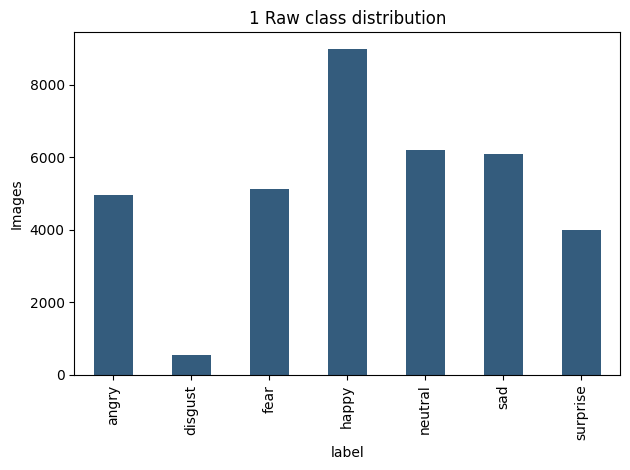

Insight: largest to smallest class ratio = 16.43 | Implication: accuracy must be accompanied by macro F1 and class recall.


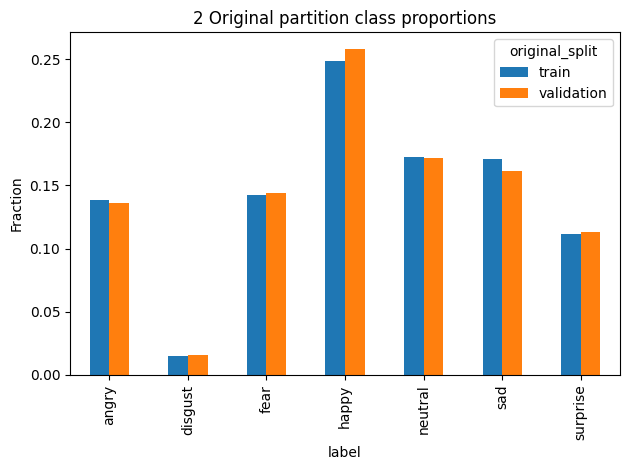

Insight: inspect differences between the supplied partition proportions; large differences can change aggregate scores.


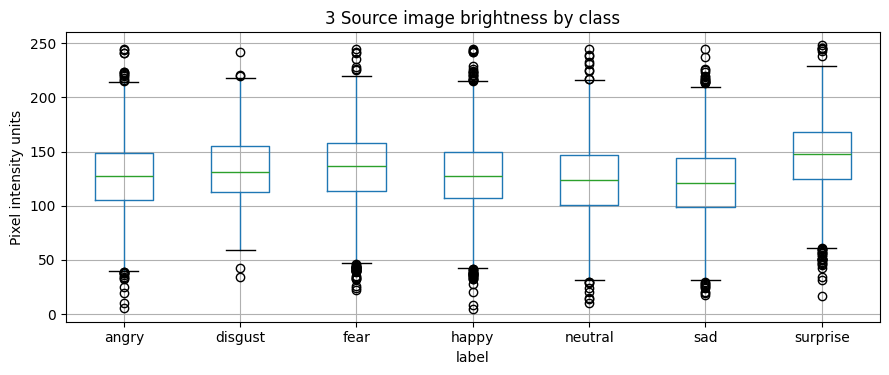

brightness class medians: {'angry': 127.37, 'disgust': 131.52, 'fear': 136.72, 'happy': 127.58, 'neutral': 123.76, 'sad': 120.98, 'surprise': 147.78} | Implication: review capture-condition differences and robustness.


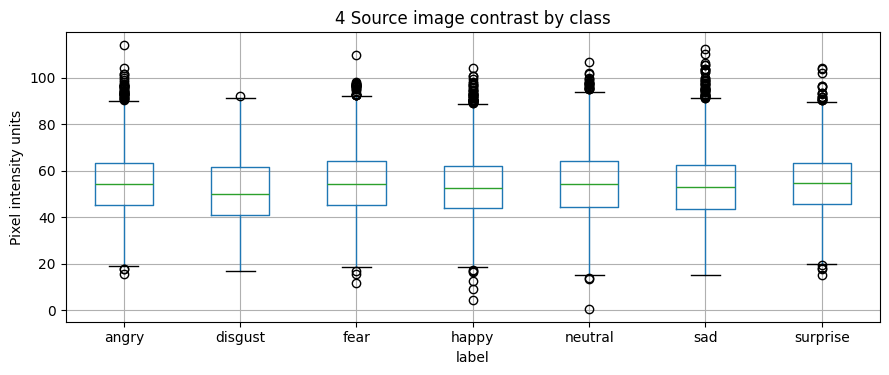

contrast class medians: {'angry': 54.19, 'disgust': 50.02, 'fear': 54.33, 'happy': 52.63, 'neutral': 54.35, 'sad': 52.84, 'surprise': 54.87} | Implication: review capture-condition differences and robustness.


In [ ]:
def finish_chart(name):
    plt.tight_layout(); plt.savefig(OUT/'charts'/f'{name}.png', dpi=160, bbox_inches='tight'); plt.show(); plt.close()
raw_counts = raw.label.value_counts().reindex(CLASSES)
raw_counts.plot.bar(title='1 Raw class distribution', ylabel='Images', color='#345c7d')
finish_chart('01_raw_classes')
print('Insight: largest to smallest class ratio =', round(raw_counts.max()/raw_counts.min(),2),
      '| Implication: accuracy must be accompanied by macro F1 and class recall.')
raw_split = pd.crosstab(raw.label,raw.original_split).reindex(CLASSES)
raw_split.div(raw_split.sum(axis=0),axis=1).plot.bar(title='2 Original partition class proportions',ylabel='Fraction')
finish_chart('02_split_proportions')
print('Insight: inspect differences between the supplied partition proportions; large differences can change aggregate scores.')
for column, number in [('brightness',3),('contrast',4)]:
    clean.boxplot(column=column,by='label',figsize=(9,4)); plt.suptitle('')
    plt.title(f'{number} Source image {column} by class'); plt.ylabel('Pixel intensity units')
    finish_chart(f'{number:02}_{column}')
    print(column, 'class medians:', clean.groupby('label')[column].median().round(2).to_dict(),
          '| Implication: review capture-condition differences and robustness.')


**Charts 5–7:** Exclusions document the cost of cleaning; retained partition counts confirm class support; augmentation examples check that transforms preserve usable face information. Exclusion counts follow a non-overlapping precedence rule and differ from raw duplicate-group totals.

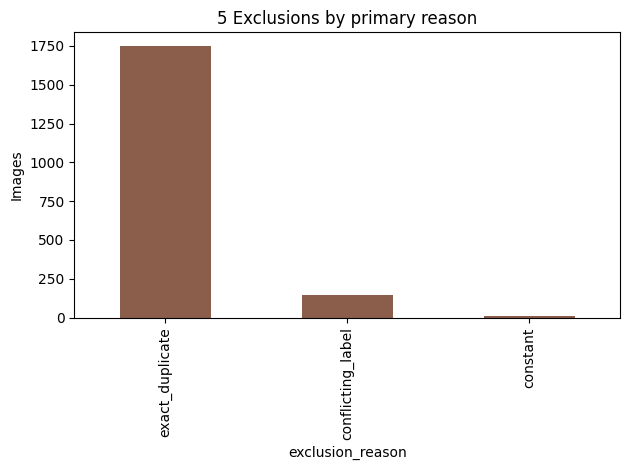

Insight: 1910 images excluded; no original files were deleted.


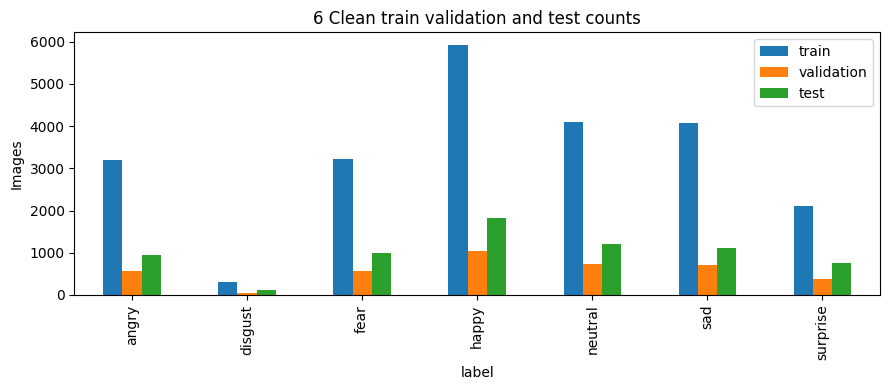

Insight: smallest fitting class has 298 images. Minority-class recall needs close review.


In [ ]:
reason_counts = excluded.exclusion_reason.value_counts()
if reason_counts.empty:
    plt.figure(); plt.text(.1,.5,'No exclusions under the declared policy'); plt.axis('off')
else:
    reason_counts.plot.bar(title='5 Exclusions by primary reason',ylabel='Images',color='#8b5d4b')
finish_chart('05_exclusions')
print('Insight:', len(excluded), 'images excluded; no original files were deleted.')
counts.plot.bar(title='6 Clean train validation and test counts',ylabel='Images',figsize=(9,4))
finish_chart('06_clean_partitions')
print('Insight: smallest fitting class has', int(counts['train'].min()), 'images. Minority-class recall needs close review.')


## 5 Feature engineering preprocessing and selection
The CNN learns spatial filters rather than using file metadata as predictors. Compare learned representations using the tuning partition only. Global average pooling reduces each final feature map to one response per channel, limiting dense-layer parameters. Channel attention tests adaptive weighting of these responses. We do not claim that particular facial features are important until interpretation is performed.

All images become 96 × 96 × 3 tensors. Replication of grayscale channels supports transfer learning; upsampling adds no original detail. CNN rescaling maps to [0,1]; MobileNetV2 rescaling maps to [-1,1]. These transforms are inside each exported model. Augmentation is active only in training mode.

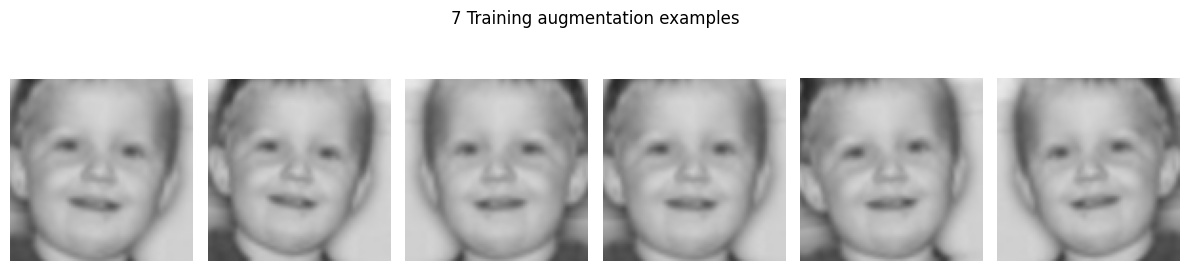

Review: expression cues should remain visible. Reduce augmentation if faces are heavily cropped or distorted.
Training-only class weights: {0: 1.0221252726706138, 1: 11.006711409395972, 2: 1.0157943635800557, 3: 0.553306342780027, 4: 0.7978594016054488, 5: 0.8060948636028509, 6: 1.550094517958412}


In [ ]:
L = tf.keras.layers
def make_augmentation():
    return tf.keras.Sequential([L.RandomFlip('horizontal', seed=SEED),
                               L.RandomRotation(.05, seed=SEED+1),
                               L.RandomZoom(.10, seed=SEED+2)], name='augmentation')
def decode_image(path, label):
    data = tf.io.read_file(path)
    image = tf.io.decode_image(data, channels=3, expand_animations=False)
    image.set_shape([None,None,3])
    image = tf.image.resize(tf.cast(image,tf.float32), [IMAGE_SIZE,IMAGE_SIZE])
    return image, label
def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.to_numpy(),frame.target.to_numpy(dtype='int32')))
    if training:
        ds = ds.shuffle(len(frame),seed=SEED,reshuffle_each_iteration=True)
    options = tf.data.Options(); options.experimental_deterministic = True
    return ds.with_options(options).map(decode_image,num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
train_ds = make_dataset(train, True); val_ds = make_dataset(val); test_ds = make_dataset(test)
sample_x, sample_y = next(iter(train_ds))
assert sample_x.shape[1:] == (IMAGE_SIZE,IMAGE_SIZE,3)
assert bool(tf.reduce_all(tf.math.is_finite(sample_x)))
aug = make_augmentation(); aug_images = aug(tf.repeat(sample_x[:1],6,axis=0),training=True).numpy()
fig, axes = plt.subplots(1,6,figsize=(12,3))
for ax, image in zip(axes,aug_images):
    ax.imshow(np.clip(image,0,255).astype('uint8')); ax.axis('off')
fig.suptitle('7 Training augmentation examples'); finish_chart('07_augmentation')
print('Review: expression cues should remain visible. Reduce augmentation if faces are heavily cropped or distorted.')
class_weights_array = compute_class_weight(class_weight='balanced',classes=np.arange(7),y=train.target)
class_weights = {int(i):float(value) for i,value in enumerate(class_weights_array)}
(OUT/'class_weights.json').write_text(json.dumps(class_weights,indent=2))
print('Training-only class weights:', class_weights)


## 6 Model implementation and optimization
The CNN has three blocks with 32, 64 and 128 filters. Each block uses two 3 × 3 convolutions with batch normalization and ReLU, followed by 2 × 2 pooling and dropout. Global pooling and a seven-class softmax finish the model. The attention variant inserts a squeeze-and-excitation unit into each block. Transfer learning uses MobileNetV2 without its original classification head.

Use Adam, balanced class weights, learning-rate reduction and early stopping. Validation macro F1 is computed before checkpoint callbacks. Candidate selection is a finite architecture and fine-tuning comparison using split-sample validation; it is not an exhaustive hyperparameter search or cross-validation. Results quantify whether attention and fine-tuning improve performance. See the cited TensorFlow workflow for the transfer stages.

In [ ]:
def build_cnn(attention=False):
    inputs = L.Input((IMAGE_SIZE,IMAGE_SIZE,3), name='image')
    x = make_augmentation()(inputs); x = L.Rescaling(1./255)(x)
    for block, filters in enumerate([32,64,128],1):
        for conv in range(2):
            x = L.Conv2D(filters,3,padding='same',use_bias=False,name=f'block{block}_conv{conv}')(x)
            x = L.BatchNormalization()(x); x = L.Activation('relu')(x)
        if attention:
            squeeze = L.GlobalAveragePooling2D()(x)
            squeeze = L.Dense(max(filters//8,4),activation='relu')(squeeze)
            squeeze = L.Dense(filters,activation='sigmoid')(squeeze)
            squeeze = L.Reshape((1,1,filters))(squeeze)
            x = L.Multiply()([x,squeeze])
        x = L.MaxPooling2D()(x); x = L.Dropout(.2)(x)
    x = L.GlobalAveragePooling2D(name='learned_features')(x)
    x = L.Dropout(.4)(x)
    outputs = L.Dense(7,activation='softmax',dtype='float32',name='expression')(x)
    return tf.keras.Model(inputs,outputs,name='attention_cnn' if attention else 'cnn')
def build_transfer():
    backbone = tf.keras.applications.MobileNetV2(input_shape=(IMAGE_SIZE,IMAGE_SIZE,3),
                                                include_top=False,weights='imagenet')
    backbone.trainable = False
    inputs = L.Input((IMAGE_SIZE,IMAGE_SIZE,3),name='image')
    x = make_augmentation()(inputs); x = L.Rescaling(1./127.5,offset=-1)(x)
    x = backbone(x,training=False)
    x = L.GlobalAveragePooling2D(name='learned_features')(x); x = L.Dropout(.4)(x)
    outputs = L.Dense(7,activation='softmax',dtype='float32')(x)
    return tf.keras.Model(inputs,outputs,name='mobilenet_classifier')

class ValidationMacroF1(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        predictions = self.model.predict(val_ds,verbose=0).argmax(axis=1)
        logs['val_macro_f1'] = f1_score(val.target,predictions,labels=np.arange(7),average='macro',zero_division=0)

def train_candidate(model,name,lr=1e-3,epochs=EPOCHS):
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    with (OUT/f'{name}_architecture.txt').open('w') as f:
        model.summary(print_fn=lambda line, **kwargs: f.write(line+'\n'))
    checkpoint = OUT/'models'/f'{name}.keras'
    callbacks = [ValidationMacroF1(),
                 tf.keras.callbacks.ModelCheckpoint(str(checkpoint),monitor='val_macro_f1',mode='max',save_best_only=True),
                 tf.keras.callbacks.EarlyStopping(monitor='val_macro_f1',mode='max',patience=7,restore_best_weights=True),
                 tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',patience=3,factor=.5),
                 tf.keras.callbacks.CSVLogger(str(OUT/f'{name}_history.csv')),
                 tf.keras.callbacks.TerminateOnNaN()]
    start = time.perf_counter()
    history = model.fit(train_ds,validation_data=val_ds,epochs=epochs,class_weight=class_weights,callbacks=callbacks)
    seconds = time.perf_counter()-start
    if not checkpoint.exists():
        raise RuntimeError(f'No valid checkpoint produced for {name}')
    restored = tf.keras.models.load_model(checkpoint)
    probs = restored.predict(val_ds,verbose=0)
    if not np.isfinite(probs).all():
        raise RuntimeError('Non-finite validation predictions')
    row = {'model':name, 'val_macro_f1':float(f1_score(val.target,probs.argmax(1),average='macro',zero_division=0)),
           'val_accuracy':float(accuracy_score(val.target,probs.argmax(1))),
           'parameters':int(restored.count_params()),'training_seconds':seconds,
           'best_epoch':int(np.argmax(history.history['val_macro_f1'])+1),
           'checkpoint':str(checkpoint)}
    del restored
    return row


In [ ]:
# Fresh runs use their own output folder. Checkpoints are saved during training.
results = []
for name, attention in [('cnn',False),('attention_cnn',True)]:
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    candidate = build_cnn(attention)
    results.append(train_candidate(candidate,name))
    pd.DataFrame(results).to_csv(OUT/'validation_comparison.csv',index=False)
    del candidate; gc.collect()
if RUN_TRANSFER:
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    candidate = build_transfer()
    results.append(train_candidate(candidate,'mobilenet_frozen'))
    del candidate; gc.collect()
    candidate = tf.keras.models.load_model(OUT/'models'/'mobilenet_frozen.keras')
    backbone = next(layer for layer in candidate.layers if isinstance(layer,tf.keras.Model))
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = False
    for layer in backbone.layers[-30:]:
        if not isinstance(layer,L.BatchNormalization):
            layer.trainable = True
    results.append(train_candidate(candidate,'mobilenet_finetuned',lr=1e-5,epochs=FINE_TUNE_EPOCHS))
    del candidate; gc.collect()
comparison = pd.DataFrame(results).sort_values(['val_macro_f1','parameters'],ascending=[False,True])
comparison.to_csv(OUT/'validation_comparison.csv',index=False)
display(comparison.drop(columns='checkpoint'))
best_row = comparison.iloc[0]
best_name = str(best_row['model'])
best = tf.keras.models.load_model(best_row['checkpoint'])
best.save(OUT/'selected_model.keras')
print('Selected using validation macro F1 only:', best_name)


Epoch 1/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 55s 61ms/step - accuracy: 0.1502 - loss: 2.0079 - val_accuracy: 0.1111 - val_loss: 2.2590 - val_macro_f1: 0.0613 - learning_rate: 0.0010
Epoch 2/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 46s 64ms/step - accuracy: 0.1620 - loss: 1.9435 - val_accuracy: 0.1318 - val_loss: 2.1798 - val_macro_f1: 0.0818 - learning_rate: 0.0010
Epoch 3/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 43s 59ms/step - accuracy: 0.1595 - loss: 1.9207 - val_accuracy: 0.0570 - val_loss: 2.3595 - val_macro_f1: 0.0544 - learning_rate: 0.0010
Epoch 4/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 43s 60ms/step - accuracy: 0.1733 - loss: 1.8861 - val_accuracy: 0.2670 - val_loss: 1.9325 - val_macro_f1: 0.1129 - learning_rate: 0.0010
Epoch 5/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 44s 61ms/step - accuracy: 0.2072 - loss: 1.8498 - val_accuracy: 0.1779 - val_loss: 1.9618 - val_macro_f1: 0.0841 - learning_rate: 0.0010
Epoch 6/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 43s 60ms/step - accuracy: 0.2422 - loss: 1.7983 - val_accuracy: 0.2127 - va

Epoch 1/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 54s 68ms/step - accuracy: 0.1624 - loss: 1.9502 - val_accuracy: 0.2258 - val_loss: 1.8707 - val_macro_f1: 0.1588 - learning_rate: 0.0010
Epoch 2/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 48s 67ms/step - accuracy: 0.1804 - loss: 1.9080 - val_accuracy: 0.2468 - val_loss: 1.8487 - val_macro_f1: 0.1892 - learning_rate: 0.0010
Epoch 3/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 48s 67ms/step - accuracy: 0.2039 - loss: 1.8606 - val_accuracy: 0.2414 - val_loss: 1.8777 - val_macro_f1: 0.1860 - learning_rate: 0.0010
Epoch 4/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 82s 67ms/step - accuracy: 0.2436 - loss: 1.8022 - val_accuracy: 0.2999 - val_loss: 1.8197 - val_macro_f1: 0.2227 - learning_rate: 0.0010
Epoch 5/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 48s 67ms/step - accuracy: 0.2772 - loss: 1.7617 - val_accuracy: 0.2391 - val_loss: 1.9201 - val_macro_f1: 0.1730 - learning_rate: 0.0010
Epoch 6/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 48s 67ms/step - accuracy: 0.2958 - loss: 1.7236 - val_accuracy: 0.3549 - va

Epoch 1/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 28s 33ms/step - accuracy: 0.2763 - loss: 2.0644 - val_accuracy: 0.3889 - val_loss: 1.5867 - val_macro_f1: 0.3191 - learning_rate: 0.0010
Epoch 2/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.3369 - loss: 1.7670 - val_accuracy: 0.4062 - val_loss: 1.5363 - val_macro_f1: 0.3546 - learning_rate: 0.0010
Epoch 3/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.3521 - loss: 1.7221 - val_accuracy: 0.4232 - val_loss: 1.5136 - val_macro_f1: 0.3586 - learning_rate: 0.0010
Epoch 4/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.3536 - loss: 1.7149 - val_accuracy: 0.3662 - val_loss: 1.6361 - val_macro_f1: 0.3179 - learning_rate: 0.0010
Epoch 5/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - accuracy: 0.3552 - loss: 1.7023 - val_accuracy: 0.3717 - val_loss: 1.6318 - val_macro_f1: 0.3292 - learning_rate: 0.0010
Epoch 6/35
718/718 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - accuracy: 0.3568 - loss: 1.6798 - val_accuracy: 0.3860 - va

Epoch 1/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.4062 - loss: 1.5199 - val_accuracy: 0.4348 - val_loss: 1.4880 - val_macro_f1: 0.3812 - learning_rate: 1.0000e-05
Epoch 2/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.4030 - loss: 1.5212 - val_accuracy: 0.4348 - val_loss: 1.4928 - val_macro_f1: 0.3819 - learning_rate: 1.0000e-05
Epoch 3/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.3986 - loss: 1.5351 - val_accuracy: 0.4339 - val_loss: 1.4909 - val_macro_f1: 0.3803 - learning_rate: 1.0000e-05
Epoch 4/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.3982 - loss: 1.5115 - val_accuracy: 0.4363 - val_loss: 1.4850 - val_macro_f1: 0.3830 - learning_rate: 1.0000e-05
Epoch 5/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - accuracy: 0.4031 - loss: 1.5111 - val_accuracy: 0.4334 - val_loss: 1.4913 - val_macro_f1: 0.3802 - learning_rate: 1.0000e-05
Epoch 6/15
718/718 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - accuracy: 0.3967 - loss: 1.5236 - val_a

,model,val_macro_f1,val_accuracy,parameters,training_seconds,best_epoch
0,cnn,0.463578,0.534551,289255,1682.231604,28
1,attention_cnn,0.453747,0.528875,294883,1767.299504,34
3,mobilenet_finetuned,0.383007,0.436328,2266951,201.226880,4
2,mobilenet_frozen,0.382797,0.432626,2266951,547.938546,23


Selected using validation macro F1 only: cnn


### Model comparison and learning behavior
**Charts 8–11:** Compare validation macro F1 and training time, then inspect validation loss and macro F1 by epoch. These charts support representation selection and show whether extra cost produces an observed benefit. One seed cannot establish a statistically reliable ranking; repeat complete fitting comparisons across seeds if time permits, while preserving the test partition.

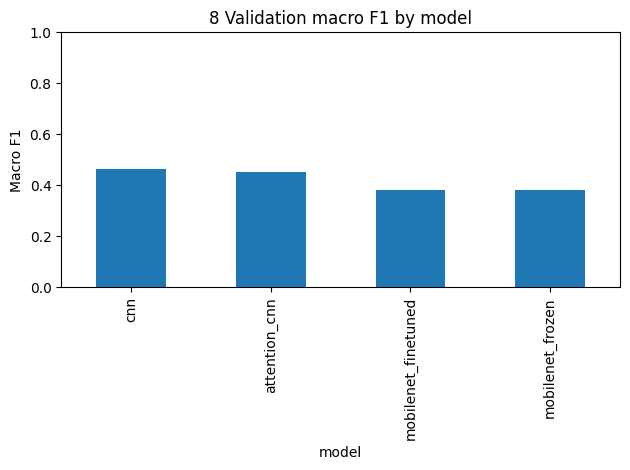

Insight: attention minus CNN validation macro F1 = -0.0098. This is a single-seed result.


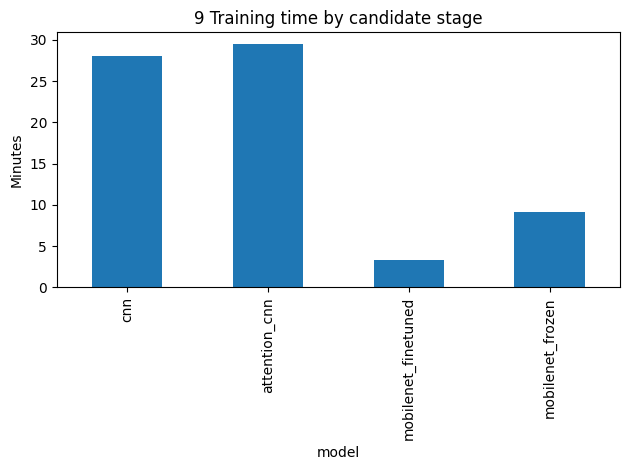

Implication: fine-tuning time is its stage cost; the complete transfer pipeline also includes frozen-head training.


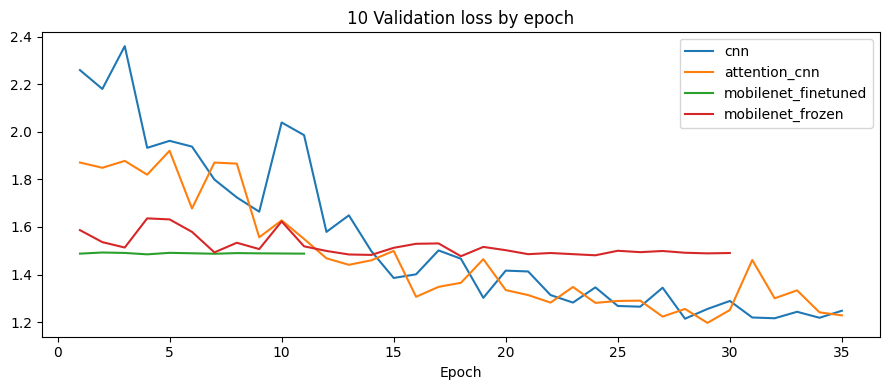

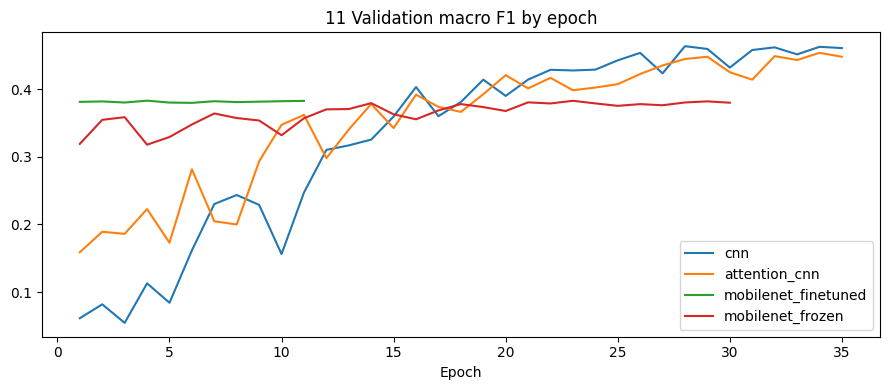

Insight: the best checkpoint may precede the final epoch. Review learning curves for instability or a plateau.


In [ ]:
comparison.set_index('model').val_macro_f1.plot.bar(title='8 Validation macro F1 by model',ylim=(0,1),ylabel='Macro F1')
finish_chart('08_validation_f1')
delta = float(comparison.set_index('model').loc['attention_cnn','val_macro_f1'] - comparison.set_index('model').loc['cnn','val_macro_f1'])
print(f'Insight: attention minus CNN validation macro F1 = {delta:+.4f}. This is a single-seed result.')
comparison.set_index('model').training_seconds.div(60).plot.bar(title='9 Training time by candidate stage',ylabel='Minutes')
finish_chart('09_training_time')
print('Implication: fine-tuning time is its stage cost; the complete transfer pipeline also includes frozen-head training.')
for number, metric, title in [(10,'val_loss','Validation loss by epoch'),(11,'val_macro_f1','Validation macro F1 by epoch')]:
    plt.figure(figsize=(9,4))
    for name in comparison.model:
        h = pd.read_csv(OUT/f'{name}_history.csv')
        plt.plot(np.arange(1,len(h)+1),h[metric],label=name)
    plt.title(f'{number} {title}'); plt.xlabel('Epoch'); plt.legend()
    finish_chart(f'{number:02}_{metric}')
print('Insight: the best checkpoint may precede the final epoch. Review learning curves for instability or a plateau.')


## 7 Evaluation and model validation
Evaluate only the selected model on the final test partition. Accuracy measures overall correctness. Precision measures the reliability of a predicted class, recall measures recovery of true examples, and macro F1 gives each class equal weight. Weighted F1 reflects prevalence. The majority-class baseline predicts the fitting partition's most frequent class. Bootstrap intervals assume independent test images and condition on one trained model; they do not capture retraining variability or subject clustering.

In [ ]:
truth = test.target.to_numpy()
probabilities = best.predict(test_ds,verbose=0)
predictions = probabilities.argmax(axis=1)
assert probabilities.shape == (len(test),7)
assert np.isfinite(probabilities).all()
np.testing.assert_allclose(probabilities.sum(axis=1),1,atol=1e-5)
report = classification_report(truth,predictions,labels=np.arange(7),target_names=CLASSES,
                               output_dict=True,zero_division=0)
report_frame = pd.DataFrame(report).T
report_frame.to_csv(OUT/'test_classification_report.csv')
display(report_frame)
majority_id = int(train.target.mode().iloc[0])
baseline = np.full(len(truth),majority_id)
summary = {'selected_model':best_name, 'selection_metric':'validation_macro_f1',
           'validation_macro_f1':float(best_row.val_macro_f1),
           'test_accuracy':float(accuracy_score(truth,predictions)),
           'test_macro_f1':float(f1_score(truth,predictions,labels=np.arange(7),average='macro',zero_division=0)),
           'test_weighted_f1':float(f1_score(truth,predictions,average='weighted',zero_division=0)),
           'test_log_loss':float(log_loss(truth,probabilities,labels=np.arange(7))),
           'majority_class':CLASSES[majority_id],
           'majority_accuracy':float(accuracy_score(truth,baseline)),
           'majority_macro_f1':float(f1_score(truth,baseline,labels=np.arange(7),average='macro',zero_division=0))}
rng = np.random.default_rng(SEED)
boot = []
for _ in range(BOOTSTRAPS):
    indices = rng.integers(0,len(truth),size=len(truth))
    boot.append(f1_score(truth[indices],predictions[indices],labels=np.arange(7),average='macro',zero_division=0))
summary['test_macro_f1_bootstrap_95_ci'] = np.percentile(boot,[2.5,97.5]).tolist()
prediction_table = test[['relative_path','label']].copy()
prediction_table['predicted_label'] = [CLASSES[i] for i in predictions]
for i, name in enumerate(CLASSES):
    prediction_table[f'p_{name}'] = probabilities[:,i]
prediction_table.to_csv(OUT/'test_predictions.csv',index=False)
(OUT/'metrics.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))


,precision,recall,f1-score,support
angry,0.427704,0.373673,0.398867,942.000000
disgust,0.203822,0.598131,0.304038,107.000000
fear,0.452308,0.146560,0.221386,1003.000000
happy,0.813509,0.747802,0.779273,1820.000000
neutral,0.468520,0.683209,0.555855,1209.000000
sad,0.438447,0.411556,0.424576,1125.000000
surprise,0.575668,0.766798,0.657627,759.000000
accuracy,0.544867,0.544867,0.544867,0.544867
macro avg,0.482854,0.532533,0.477374,6965.000000
weighted avg,0.553565,0.544867,0.530855,6965.000000


{
  "selected_model": "cnn",
  "selection_metric": "validation_macro_f1",
  "validation_macro_f1": 0.4635782592174775,
  "test_accuracy": 0.5448671931083992,
  "test_macro_f1": 0.4773744112035607,
  "test_weighted_f1": 0.5308551344020306,
  "test_log_loss": 1.2071846681631775,
  "majority_class": "happy",
  "majority_accuracy": 0.2613065326633166,
  "majority_macro_f1": 0.059191804211724534,
  "test_macro_f1_bootstrap_95_ci": [
    0.46447397975520754,
    0.4898933610701261
  ]
}


**Charts 12–14:** Count and row-normalized confusion matrices identify error volumes and class recall. Per-class metric bars expose minority-class weaknesses hidden by accuracy. Their practical use is prioritizing additional labeled examples and error review; an actual business outcome is not inferred.

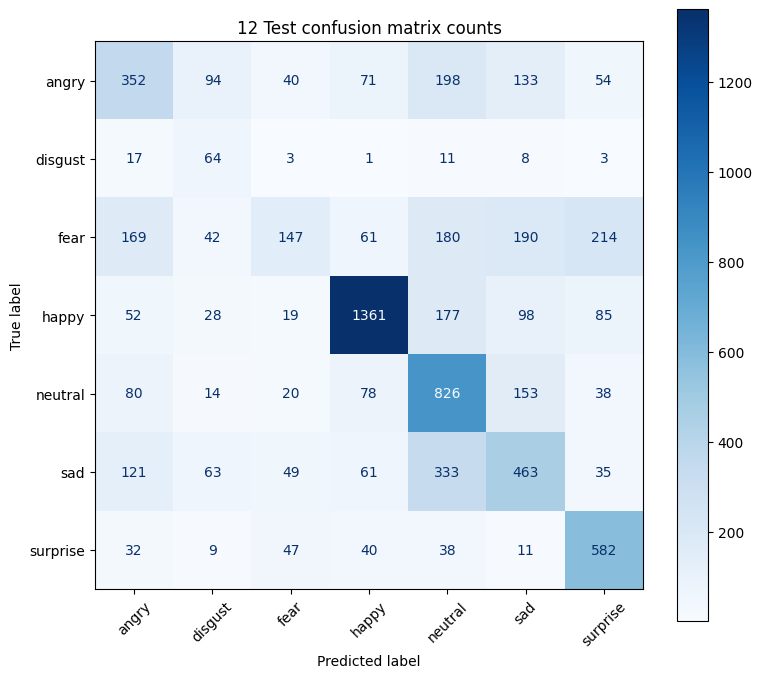

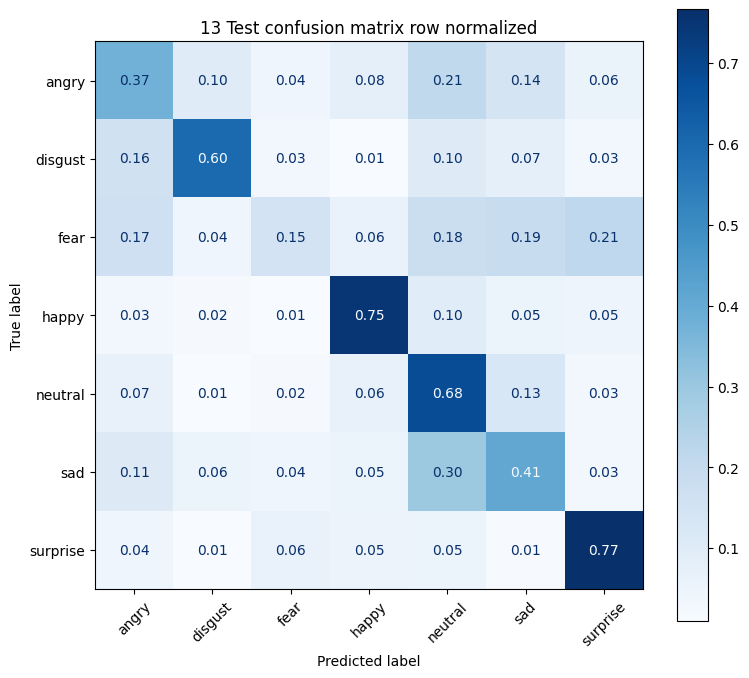

Largest off-diagonal pair: sad → neutral count: 333


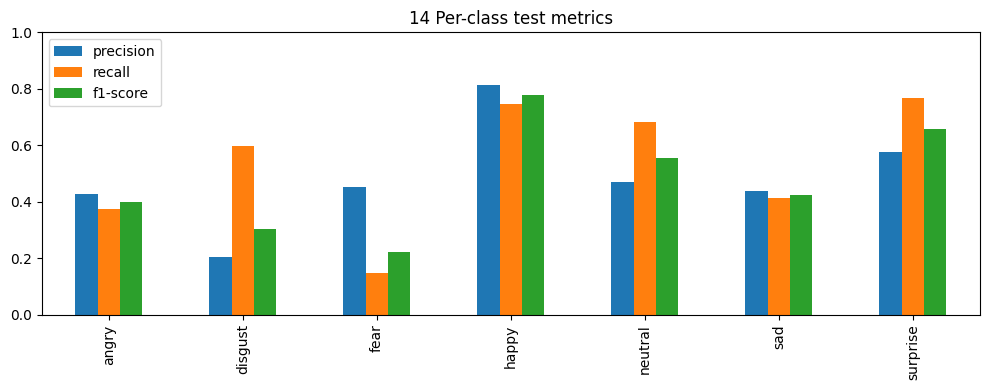

Lowest recall class: fear | Implication: review its errors before application use.


In [ ]:
for number, normalize in [(12,None),(13,'true')]:
    fig, ax = plt.subplots(figsize=(8,7))
    ConfusionMatrixDisplay.from_predictions(truth,predictions,labels=np.arange(7),display_labels=CLASSES,
                                           normalize=normalize,xticks_rotation=45,ax=ax,
                                           values_format='.2f' if normalize else 'd',cmap='Blues')
    ax.set_title(f'{number} Test confusion matrix' + (' row normalized' if normalize else ' counts'))
    finish_chart(f'{number:02}_confusion')
cm = confusion_matrix(truth,predictions,labels=np.arange(7))
off = cm.copy(); np.fill_diagonal(off,0)
i,j = np.unravel_index(off.argmax(),off.shape)
print('Largest off-diagonal pair:',CLASSES[i],'→',CLASSES[j], 'count:',int(off[i,j]))
class_metrics = report_frame.loc[CLASSES,['precision','recall','f1-score']]
class_metrics.plot.bar(title='14 Per-class test metrics',ylim=(0,1),figsize=(10,4))
finish_chart('14_class_metrics')
print('Lowest recall class:',class_metrics.recall.idxmin(), '| Implication: review its errors before application use.')


**Charts 15–17:** Confidence distributions compare correct and incorrect predictions. A reliability diagram compares average maximum score with empirical correctness using fixed bins; no calibration method is fitted on test data. The error gallery illustrates failure cases rather than estimating population-wide performance. High-confidence mistakes warrant investigation, and low sample counts make calibration bins uncertain.

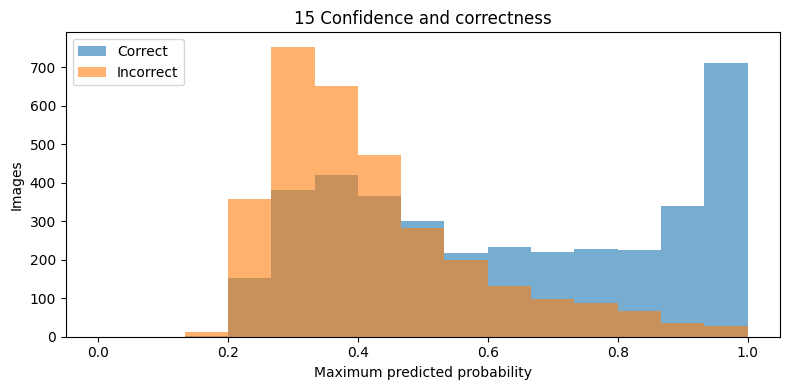

High-confidence errors above 0.9: 44


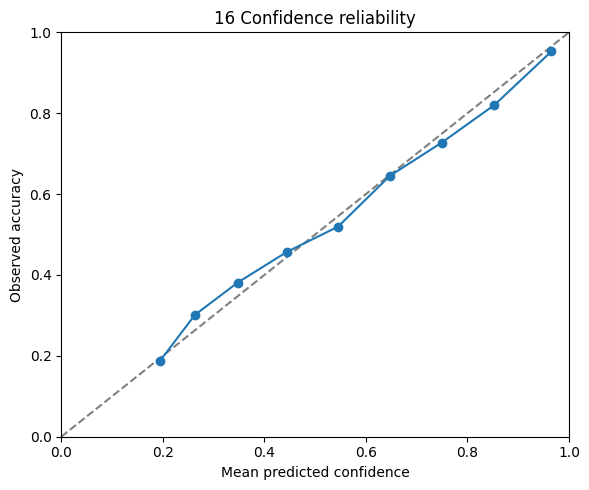

Binned expected calibration error: 0.024 | This is a diagnostic, not proof of calibrated confidence.


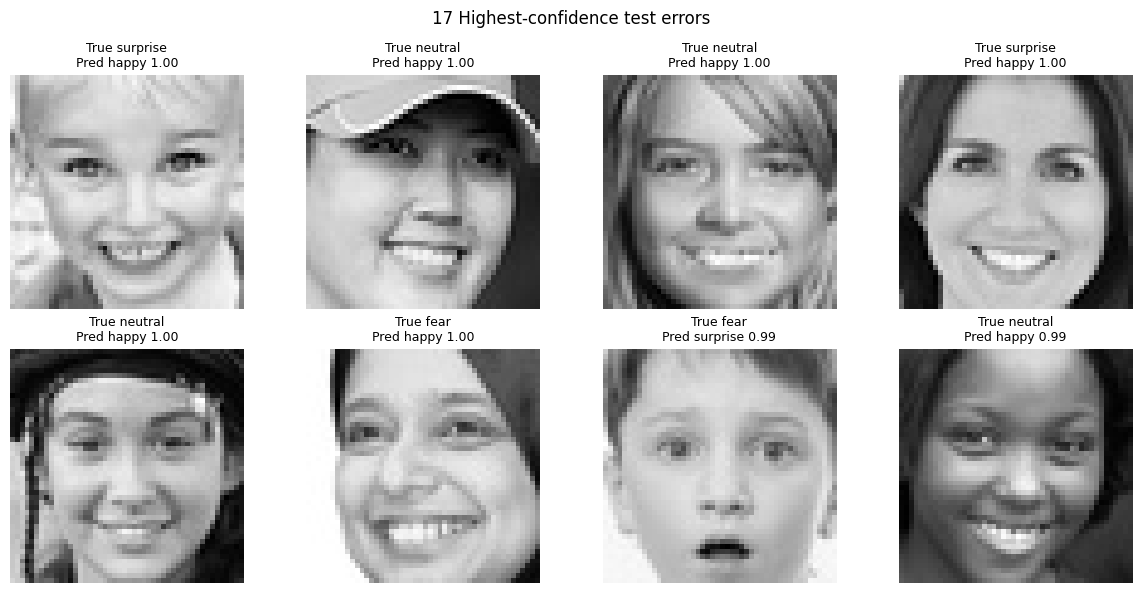

In [ ]:
confidence = probabilities.max(axis=1); correct = predictions == truth
plt.figure(figsize=(8,4))
for mask, label in [(correct,'Correct'),(~correct,'Incorrect')]:
    plt.hist(confidence[mask],bins=np.linspace(0,1,16),alpha=.6,label=label)
plt.xlabel('Maximum predicted probability'); plt.ylabel('Images'); plt.title('15 Confidence and correctness'); plt.legend()
finish_chart('15_confidence')
print('High-confidence errors above 0.9:',int(((confidence>.9)&(~correct)).sum()))
bin_ids = np.minimum((confidence*10).astype(int),9)
reliability = pd.DataFrame({'bin':bin_ids,'confidence':confidence,'correct':correct}).groupby('bin').agg(
    mean_confidence=('confidence','mean'),accuracy=('correct','mean'),count=('correct','size'))
reliability.to_csv(OUT/'reliability_bins.csv')
plt.figure(figsize=(6,5)); plt.plot([0,1],[0,1],'--',color='gray')
plt.plot(reliability.mean_confidence,reliability.accuracy,'o-')
plt.xlim(0,1);plt.ylim(0,1);plt.xlabel('Mean predicted confidence');plt.ylabel('Observed accuracy')
plt.title('16 Confidence reliability');finish_chart('16_reliability')
ece = float(np.sum(reliability['count']*abs(reliability.mean_confidence-reliability.accuracy))/len(test))
summary['expected_calibration_error_10_bins'] = ece
print('Binned expected calibration error:',round(ece,4),'| This is a diagnostic, not proof of calibrated confidence.')
error_indices = np.flatnonzero(~correct)
chosen = error_indices[np.argsort(confidence[error_indices])[::-1]][:8]
fig, axes = plt.subplots(2,4,figsize=(12,6))
for ax in axes.flat: ax.axis('off')
for ax, idx in zip(axes.flat,chosen):
    with Image.open(test.iloc[idx].path) as image: ax.imshow(image.convert('L'),cmap='gray')
    ax.set_title(f'True {CLASSES[truth[idx]]}\nPred {CLASSES[predictions[idx]]} {confidence[idx]:.2f}',fontsize=9)
fig.suptitle('17 Highest-confidence test errors' if len(chosen) else '17 No test errors observed')
finish_chart('17_error_gallery')


## 8 Interpretability and inference
**Chart 18:** Occlusion sensitivity records the predicted class-score drop after covering image patches with the image mean. Positive values indicate that hiding the patch lowered that score. This is model sensitivity, not causal evidence or proof of internal emotion. One example per class is selected deterministically; inspect both correct and incorrect examples in a fuller study.

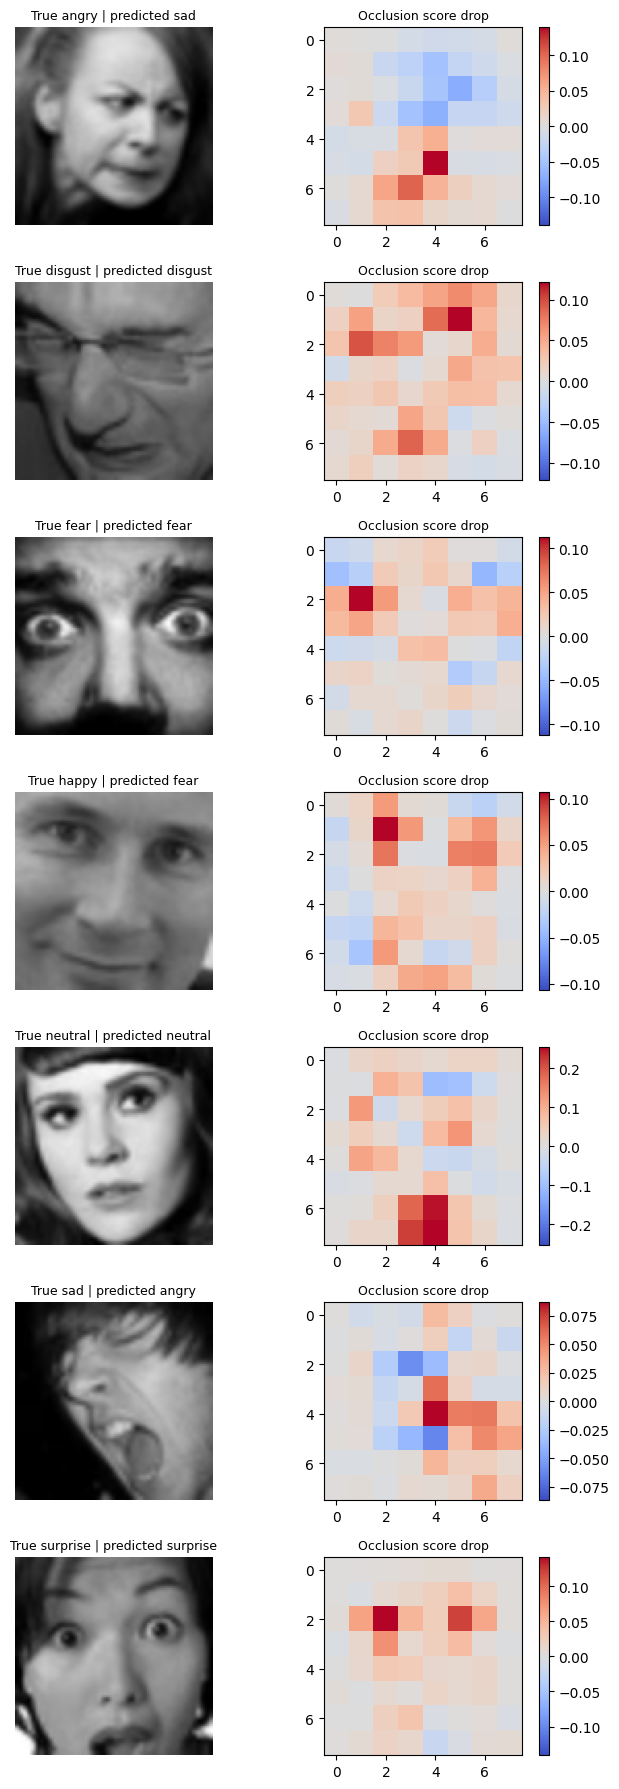

In [ ]:
fig, axes = plt.subplots(7,2,figsize=(7,18))
for class_id in range(7):
    idx = int(np.flatnonzero(truth==class_id)[0])
    image_tensor,_ = decode_image(tf.constant(test.iloc[idx].path),tf.constant(class_id))
    image = image_tensor.numpy(); original = best(image[None],training=False).numpy()[0]
    target = int(original.argmax()); patches = []; positions = []
    edges = np.linspace(0,IMAGE_SIZE,9,dtype=int)
    for row in range(8):
        for col in range(8):
            masked = image.copy(); masked[edges[row]:edges[row+1],edges[col]:edges[col+1],:] = image.mean()
            patches.append(masked); positions.append((row,col))
    occluded = best.predict(np.asarray(patches),batch_size=BATCH_SIZE,verbose=0)
    heat = (original[target]-occluded[:,target]).reshape(8,8)
    axes[class_id,0].imshow(np.clip(image,0,255).astype('uint8')); axes[class_id,0].axis('off')
    axes[class_id,0].set_title(f'True {CLASSES[class_id]} | predicted {CLASSES[target]}',fontsize=9)
    limit = max(float(abs(heat).max()),1e-6)
    visual = axes[class_id,1].imshow(heat,cmap='coolwarm',vmin=-limit,vmax=limit)
    axes[class_id,1].set_title('Occlusion score drop',fontsize=9); fig.colorbar(visual,ax=axes[class_id,1])
finish_chart('18_occlusion')


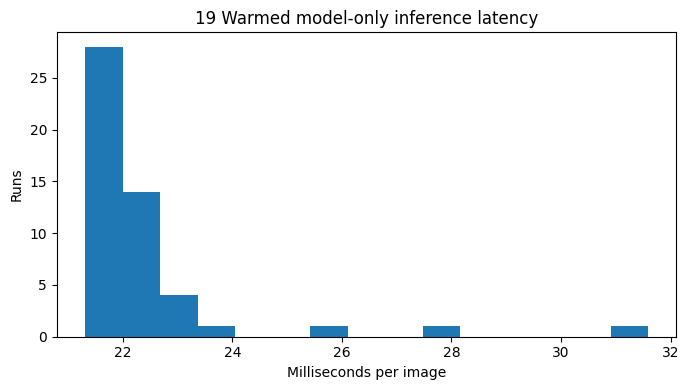

{'median': 21.921827500136715, 'p95': 24.905826050280663, 'batch_size': 1, 'iterations': 50}
Excludes capture, detection, preprocessing and display. A real-time video claim is not established.


,probability
sad,0.387990
angry,0.234905
fear,0.194270
neutral,0.106474
happy,0.043540
disgust,0.022548
surprise,0.010273


In [ ]:
# Model-only batch-one timing. Conversion to NumPy synchronizes computation.
one, _ = next(iter(test_ds)); one = one[:1]
for _ in range(10): best(one,training=False).numpy()
latencies = []
for _ in range(50):
    start = time.perf_counter(); best(one,training=False).numpy()
    latencies.append(1000*(time.perf_counter()-start))
summary['model_only_latency_ms'] = {'median':float(np.median(latencies)),'p95':float(np.percentile(latencies,95)),
                                    'batch_size':1,'iterations':50}
plt.figure(figsize=(7,4));plt.hist(latencies,bins=15)
plt.xlabel('Milliseconds per image');plt.ylabel('Runs');plt.title('19 Warmed model-only inference latency')
finish_chart('19_latency')
print(summary['model_only_latency_ms'])
print('Excludes capture, detection, preprocessing and display. A real-time video claim is not established.')

def predict_face(image_path, model=best):
    # Input must already be a cropped face. This function does not detect faces.
    with Image.open(image_path) as source:
        rgb = np.asarray(source.convert('RGB'),dtype=np.float32)
    tensor = tf.image.resize(rgb,[IMAGE_SIZE,IMAGE_SIZE]).numpy()
    scores = model(tensor[None],training=False).numpy()[0]
    return pd.Series(scores,index=CLASSES,name='probability').sort_values(ascending=False)
display(predict_face(test.iloc[0].path))
if RUN_IMAGE_UPLOAD_DEMO:
    from google.colab import files
    for name in files.upload():
        display(predict_face(name))


## 9 Save the model and verify reloading
Use Keras serialization rather than pickle for neural network weights and architecture. Saved preprocessing is part of the model. Verify identical output after reloading, then export a results archive. Drive copies persist beyond a runtime session; local `/content` files do not.

In [ ]:
metadata = {'classes':CLASSES,'input_shape':[IMAGE_SIZE,IMAGE_SIZE,3],
            'input_range':[0,255],'input_type':'cropped RGB face; grayscale repeated to RGB is allowed',
            'resize':'TensorFlow bilinear','normalization':'embedded in model',
            'selected_model':best_name,'limitations':['No face detector','No identity-disjoint guarantee',
                                                     'Expression classification is not internal emotion assessment']}
(OUT/'inference_metadata.json').write_text(json.dumps(metadata,indent=2))
(OUT/'class_names.json').write_text(json.dumps(CLASSES))
reloaded = tf.keras.models.load_model(OUT/'selected_model.keras')
np.testing.assert_allclose(best(one,training=False).numpy(),reloaded(one,training=False).numpy(),rtol=1e-5,atol=1e-6)
print('Reload verification passed.')
(OUT/'metrics.json').write_text(json.dumps(summary,indent=2))
result_text = f'''# DeepFER executed results

Run: {run_id}

Raw images: {len(raw):,}; retained: {len(clean):,}; exclusions: {len(excluded):,}.
Fit / tuning / final test: {len(train):,} / {len(val):,} / {len(test):,}.

Selected model: {best_name}, using validation macro F1 {float(best_row.val_macro_f1):.4f}.
Final test accuracy: {summary['test_accuracy']:.4f}.
Final test macro F1: {summary['test_macro_f1']:.4f}.
Final test weighted F1: {summary['test_weighted_f1']:.4f}.
Bootstrap 95% interval for macro F1: {summary['test_macro_f1_bootstrap_95_ci']}.
Majority-class test accuracy: {summary['majority_accuracy']:.4f}.
Attention minus CNN validation macro F1: {delta:+.4f}.

The validation ranking is based on one seed. Exact duplicate overlap was checked;
near duplicates and subject identity overlap remain possible. Model-only timing
does not establish real-time video performance. See CSV files and charts for
class-level results and confidence diagnostics.
'''
(OUT/'Executed_Results.md').write_text(result_text)
display(Markdown(result_text))
archive_path = shutil.make_archive(str(Path('/content')/('DeepFER_Results_'+run_id)),'zip',OUT)
if SAVE_TO_DRIVE:
    shutil.copy2(archive_path,results_base/Path(archive_path).name)
print('Results folder:',OUT)
print('Results ZIP:',archive_path)
from google.colab import files
files.download(archive_path)


Reload verification passed.


# DeepFER executed results

Run: 20261110T072531_793329Z

Raw images: 35,887; retained: 33,977; exclusions: 1,910.
Fit / tuning / final test: 22,960 / 4,052 / 6,965.

Selected model: cnn, using validation macro F1 0.4636.
Final test accuracy: 0.5449.
Final test macro F1: 0.4774.
Final test weighted F1: 0.5309.
Bootstrap 95% interval for macro F1: [0.46447397975520754, 0.4898933610701261].
Majority-class test accuracy: 0.2613.
Attention minus CNN validation macro F1: -0.0098.

The validation ranking is based on one seed. Exact duplicate overlap was checked;
near duplicates and subject identity overlap remain possible. Model-only timing
does not establish real-time video performance. See CSV files and charts for
class-level results and confidence diagnostics.


Results folder: /content/drive/MyDrive/DeepFER_Runs/20261110T072531_793329Z
Results ZIP: /content/DeepFER_Results_20261110T072531_793329Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10 Conclusions and next steps
Use `Executed_Results.md` to update the project report with actual numbers. Explain whether attention and transfer learning improve validation macro F1, whether errors concentrate in low-support classes, and whether extra computation is justified. Preserve negative results. Do not claim superiority from a single seed or claim fairness without suitable metadata.

For further work, obtain dataset provenance and subject identifiers, review near duplicates, repeat selected experiments across seeds, evaluate on an independent source, and assess a full face-detection/video pipeline. Customer satisfaction and clinical applications require separate validation.

### Rubric mapping
| Criterion | Weight | Notebook evidence |
|---|---:|---|
| Integrity and cleaning | 10% | Decode audit, exclusions, conflict quarantine and hash assertions |
| Feature engineering and selection | 20% | CNN representations, global pooling, attention and transfer comparison |
| Preprocessing | 15% | Resizing, saved normalization, label mapping, train-only augmentation |
| Architecture | 20% | CNN, attention module and MobileNetV2 implementations |
| Training efficiency | 10% | Batches, prefetching, learning rates, stopping and timing |
| Evaluation | 15% | Stratified tuning, sealed test, metrics, bootstrap and error analysis |
| Innovation | 5% | Controlled application of channel attention and fine-tuning |
| Documentation and interpretation | 5% | Nineteen visual outputs, occlusion analysis and exported evidence |

### References
- [Submission template](https://colab.research.google.com/drive/10B2s5af8INkHgIz_7XBjW3iNDbGY7ltx)
- [TensorFlow transfer learning and fine-tuning](https://www.tensorflow.org/tutorials/images/transfer_learning)
- [MobileNetV2 documentation](https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2)
- [MobileNetV2 paper](https://arxiv.org/abs/1801.04381)
- [Squeeze-and-Excitation Networks](https://arxiv.org/abs/1709.01507)
- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)